In [2]:
%pip install -U langgraph langchain-openai langchain-tavily python-dotenv

  Using cached langgraph-1.2.15-py3-none-any.whl.metadata (4.9 kB)
  Using cached langchain_openai-1.7.1-py3-none-any.whl.metadata (3.6 kB)
  Using cached langchain_tavily-0.2.18-py3-none-any.whl.metadata (20 kB)
  Using cached python_dotenv-1.2.4-py3-none-any.whl.metadata (29 kB)
  Using cached langchain_core-1.6.10-py3-none-any.whl.metadata (4.8 kB)
  Using cached langgraph_checkpoint-4.3.0-py3-none-any.whl.metadata (6.7 kB)
  Using cached langgraph_prebuilt-1.1.0-py3-none-any.whl.metadata (5.2 kB)
  Using cached langgraph_sdk-0.4.7-py3-none-any.whl.metadata (5.1 kB)
  Using cached certifi-2026.7.22-py3-none-any.whl.metadata (2.5 kB)
  Using cached langchain-1.4.5-py3-none-any.whl.metadata (6.2 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached aiohappyeyeballs-2.7.1-py3-none-any.whl.metadata (5.9 kB)
  Using cached aiosignal-1.4.0-py3-none-any.whl.metadata (3.7 kB)
  Using cached attrs-26.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached httpx-0


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
from typing import TypedDict, Annotated, Optional
from langgraph.graph import StateGraph, add_messages, END
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from langchain_tavily import TavilySearch
from langgraph.checkpoint.memory import InMemorySaver
from uuid import uuid4
import json

load_dotenv()

model = ChatOpenAI(model="gpt-4o-mini")


In [2]:
search_tool = TavilySearch(max_results=4)

tools = [search_tool]

memory = InMemorySaver()

llm_with_tools = model.bind_tools(tools=tools)

In [3]:
from langchain_core.messages import AIMessage, HumanMessage, ToolMessage
from langgraph.prebuilt import ToolNode

class State(TypedDict):
    messages: Annotated[list, add_messages]

async def model(state: State):
    result = await llm_with_tools.ainvoke(state["messages"])
    return {
        "messages": [result], 
    }

async def tools_router(state: State):
    last_message = state["messages"][-1]

    if(hasattr(last_message, "tool_calls") and len(last_message.tool_calls) > 0):
        return "tool_node"
    else: 
        return END
    
tool_node = ToolNode(tools=tools)

graph_builder = StateGraph(State)

graph_builder.add_node("model", model)
graph_builder.add_node("tool_node", tool_node)
graph_builder.set_entry_point("model")

graph_builder.add_conditional_edges("model", tools_router)
graph_builder.add_edge("tool_node", "model")

graph = graph_builder.compile(checkpointer=memory)

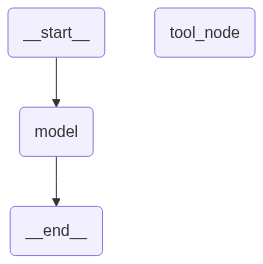

In [4]:
from IPython.display import Image, display
from langchain_core.runnables.graph import MermaidDrawMethod

display(
    Image(
        graph.get_graph().draw_mermaid_png(
            draw_method=MermaidDrawMethod.API
        )
    )
)

In [5]:
config = {
    "configurable": {
        "thread_id": 5
    }
}

response = await graph.ainvoke({
    "messages": [HumanMessage(content="When is the next SpaceX launch")], 
}, config=config)

response

{'messages': [HumanMessage(content='When is the next SpaceX launch', additional_kwargs={}, response_metadata={}, id='82e73669-d086-47d4-851e-41e0f58f9630'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 24, 'prompt_tokens': 1194, 'total_tokens': 1218, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 1152, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_e66d5cb50b', 'id': 'chatcmpl-EYuElZXJQeYW6bGfAKufeQlJKRhSa', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a13acf-6c6c-76e1-b31c-26ebbfa9b438-0', tool_calls=[{'name': 'tavily_search', 'args': {'query': 'next SpaceX launch schedule', 'top

In [9]:
config = {
    "configurable": {
        "thread_id": 8
    }
}

# Use async for to iterate over the async generator
async for event in graph.astream_events({
    "messages": [HumanMessage(content="When is the next spacex launch?")],
}, config=config, version="v2"):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='When is the next spacex launch?', additional_kwargs={}, response_metadata={})]}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a13aee-4f5f-76b2-a14b-ede20e14cbe4', 'metadata': {'thread_id': 8, 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='When is the next spacex launch?', additional_kwargs={}, response_metadata={}, id='b95d3c7c-d1d8-4487-9631-42946cbed559'), AIMessage(content='', additional_kwargs={}, response_metadata={'finish_reason': 'tool_calls', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_e66d5cb50b', 'service_tier': 'default', 'model_provider': 'openai'}, id='lc_run--01a13ad0-2e2e-7980-b9ae-563be45d5bfb', tool_calls=[{'name': 'tavily_search', 'args': {'query': 'next SpaceX launch schedule', 'time_range': 'week', 'topic': 'news'}, 'id': 'call_WCH25ohFAHYQHwubML1uzUBl', 'type': 'tool_call'}], i